# So sánh PhoBERT, XLM-R và mBERT cho POS tagging tiếng Việt (5 nhãn)

**Quy trình**
1. **PhoBERT**: dùng model bạn đã fine-tune (`huycdt/phobert_pos5`), chỉ chấm trên tập test, không train lại.
2. **XLM-R** và **mBERT**: fine-tune lại **đúng cách đã làm với PhoBERT** (cùng dữ liệu, cùng siêu tham số, cùng cách căn nhãn, cùng cách dừng sớm).
3. Chấm cả ba model trên **cùng tập test**, vẽ bảng và biểu đồ so sánh.

**Về tiền xử lý:** mỗi model dùng đúng dạng đầu vào mà nó được pretrain.
- PhoBERT: các từ đã tách, từ ghép nối bằng `_` (cột `tokens_phobert`).
- XLM-R, mBERT: chữ bình thường, từ ghép có dấu cách (cột `tokens_original`).
- Phần còn lại giống hệt nhau: cùng câu, cùng ranh giới từ, cùng nhãn, cùng cách lấy nhãn ở subword đầu của mỗi từ, cùng độ đo.

**Cần chuẩn bị:** bật GPU (Runtime → Change runtime type → T4 GPU) và có sẵn 3 file `train_pos5.csv`, `dev_pos5.csv`, `test_pos5.csv`.

## 1. Import và cấu hình

In [1]:
import os, gc, json, shutil
import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForTokenClassification, set_seed
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

LABELS   = ["Noun", "Verb", "Adjective", "Adverb", "Other"]
label2id = {lab: i for i, lab in enumerate(LABELS)}
id2label = {i: lab for i, lab in enumerate(LABELS)}

# Cấu hình huấn luyện: GIỮ NGUYÊN như lúc fine-tune PhoBERT
BATCH_SIZE = 32      # theo Nguyen & Nguyen (2020)
LR         = 1e-5    # theo Nguyen & Nguyen (2020)
MAX_EPOCHS = 30      # theo Nguyen & Nguyen (2020)
PATIENCE   = 5       # dừng sớm sau 5 epoch Accuracy trên Dev không tăng
MAX_LEN    = 256     # giới hạn subword (XLM-R và mBERT chịu được tới 512 nên 256 là an toàn)
SEED       = 42

# Cột từ dùng cho từng nhóm model (xem phần giải thích ở đầu notebook)
COT_PHOBERT = "tokens_phobert"    # từ ghép nối bằng "_"
COT_KHAC    = "tokens_original"   # từ ghép có dấu cách. Muốn thử cách khác thì đổi thành "tokens_phobert"

OUT_DIR = "/content/ket_qua"      # nơi lưu model, log, dự đoán, biểu đồ
os.makedirs(OUT_DIR, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if device == "cuda" else "không có (chạy bằng CPU, sẽ rất chậm)")
print("PyTorch", torch.__version__, "| Transformers", transformers.__version__)

GPU: Tesla T4
PyTorch 2.14.1+cu130 | Transformers 5.22.1


## 2. Nạp dữ liệu train, dev, test

In [2]:
from google.colab import files
files.upload()   # chọn cùng lúc 3 file: train_pos5.csv, dev_pos5.csv, test_pos5.csv

def doc_du_lieu(ten):
    df = pd.read_csv(f"{ten}_pos5.csv", encoding="utf-8-sig")
    for c in ["tokens_original", "tokens_phobert", "labels"]:
        df[c] = df[c].apply(json.loads)          # các cột này lưu dạng chuỗi JSON, đổi về list
    assert all(len(w) == len(t) for w, t in zip(df["tokens_original"], df["labels"])), "Số từ khác số nhãn"
    assert all(len(w) == len(t) for w, t in zip(df["tokens_phobert"],  df["labels"])), "Số từ khác số nhãn"
    return df

train, dev, test = doc_du_lieu("train"), doc_du_lieu("dev"), doc_du_lieu("test")

Saving dev_pos5.csv to dev_pos5.csv
Saving test_pos5.csv to test_pos5.csv
Saving train_pos5.csv to train_pos5.csv


**Kiểm tra 2:** số câu, số từ, nhãn và trùng câu giữa các tập.

In [3]:
for ten, df in [("Train", train), ("Dev", dev), ("Test", test)]:
    nhan = [t for ls in df["labels"] for t in ls]
    print(f"{ten:5}: {len(df)} câu | {len(nhan)} từ | " + " | ".join(f"{l} {nhan.count(l)}" for l in LABELS))

# Kỳ vọng: Train 1389 câu / 16590 từ, Dev 1121 câu / 21645 từ, Test 793 câu / 9685 từ
trung = set(train["text_phobert"]) & set(test["text_phobert"])
print("Số câu trùng giữa Train và Test:", len(trung), "(kỳ vọng 0)")

Train: 1389 câu | 16590 từ | Noun 6467 | Verb 4284 | Adjective 1095 | Adverb 1478 | Other 3266
Dev  : 1121 câu | 21645 từ | Noun 8859 | Verb 5469 | Adjective 1561 | Adverb 1641 | Other 4115
Test : 793 câu | 9685 từ | Noun 3561 | Verb 2376 | Adjective 719 | Adverb 1020 | Other 2009
Số câu trùng giữa Train và Test: 0 (kỳ vọng 0)


## 3. Các hàm dùng chung cho mọi model

Đây là code huấn luyện cũ của PhoBERT, chỉ sửa để nhận `tokenizer` làm tham số, nên cả ba model đi qua **cùng một đường ống**:
subword đầu của mỗi từ mang nhãn, các subword còn lại và token đặc biệt có nhãn `-100` (bị bỏ qua khi tính loss và khi chấm điểm).

In [4]:
def encode(tokenizer, words, tags):
    """Đổi 1 câu thành (ids, nhãn): subword đầu của mỗi từ mang nhãn, chỗ khác là -100."""
    ids, labels = [tokenizer.cls_token_id], [-100]
    for word, tag in zip(words, tags):
        pieces = tokenizer.encode(word, add_special_tokens=False) or [tokenizer.unk_token_id]
        ids    += pieces
        labels += [label2id[tag]] + [-100] * (len(pieces) - 1)
    ids.append(tokenizer.sep_token_id)
    labels.append(-100)
    return ids, labels

def tao_loader(tokenizer, df, cot_tu, shuffle=False):
    """Tạo DataLoader: gom 32 câu thành 1 batch, đệm câu ngắn bằng <pad>."""
    data = [encode(tokenizer, w, t) for w, t in zip(df[cot_tu], df["labels"])]
    dai_nhat = max(len(ids) for ids, _ in data)
    assert dai_nhat <= MAX_LEN, f"Có câu dài {dai_nhat} subword, vượt giới hạn {MAX_LEN}"
    pad_id = tokenizer.pad_token_id

    def collate(batch):
        n = max(len(ids) for ids, _ in batch)
        input_ids, mask, labels = [], [], []
        for ids, labs in batch:
            pad = n - len(ids)
            input_ids.append(ids + [pad_id] * pad)
            mask.append([1] * len(ids) + [0] * pad)        # 1 = token thật, 0 = token đệm
            labels.append(labs + [-100] * pad)
        return torch.tensor(input_ids), torch.tensor(mask), torch.tensor(labels)

    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=shuffle, collate_fn=collate)

def evaluate(model, loader):
    """Chỉ chấm ở subword đầu của mỗi từ (nhãn khác -100)."""
    model.eval()
    total_loss, y_true, y_pred = 0, [], []
    with torch.no_grad():
        for input_ids, mask, labels in loader:
            input_ids, mask, labels = input_ids.to(device), mask.to(device), labels.to(device)
            out = model(input_ids=input_ids, attention_mask=mask, labels=labels)
            total_loss += out.loss.item()
            keep = labels != -100
            y_true += labels[keep].tolist()
            y_pred += out.logits.argmax(dim=-1)[keep].tolist()
    acc      = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, labels=list(range(len(LABELS))), average="macro", zero_division=0)
    return total_loss / len(loader), acc, macro_f1, y_true, y_pred

**Kiểm tra 3:** xem cách căn nhãn trên một câu. Mỗi từ phải có đúng 1 nhãn, kể cả khi bị tách thành nhiều subword.

In [5]:
def in_can_chinh(ten_model, cot_tu, i=1):
    tok = AutoTokenizer.from_pretrained(ten_model)
    ids, labs = encode(tok, train.loc[i, cot_tu], train.loc[i, "labels"])
    print(f"--- {ten_model} (cột {cot_tu}) ---")
    for token, lab in zip(tok.convert_ids_to_tokens(ids), labs):
        print(f"{token:15} {id2label.get(lab, '-100')}")
    n_tu = len(train.loc[i, "labels"])
    assert sum(l != -100 for l in labs) == n_tu, "Số nhãn khác số từ"

in_can_chinh("xlm-roberta-base", COT_KHAC)
in_can_chinh("bert-base-multilingual-cased", COT_KHAC)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

--- xlm-roberta-base (cột tokens_original) ---
<s>             -100
▁Hiện           Noun
▁nay            -100
▁xã             Noun
▁có             Verb
▁tổ             Noun
▁nhân           Noun
▁dân            -100
▁tổ             Noun
▁phụ            Verb
▁trách          -100
▁gia            Noun
▁đình           -100
</s>            -100


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

--- bert-base-multilingual-cased (cột tokens_original) ---
[CLS]           -100
Hiện            Noun
nay             -100
xã              Noun
có              Verb
tổ              Noun
nhân            Noun
dân             -100
tổ              Noun
phụ             Verb
trách           -100
gia             Noun
đình            -100
[SEP]           -100


## 4. Hàm fine-tune (giống hệt cách huấn luyện PhoBERT)

AdamW với `lr = 1e-5` (không scheduler, không warmup), batch 32, tối đa 30 epoch, lưu model có Accuracy trên Dev cao nhất, dừng sớm sau 5 epoch không cải thiện, seed 42.

In [6]:
HISTORY = {}   # lưu log huấn luyện của từng model để vẽ biểu đồ

def fine_tune(ten, model_name, cot_tu):
    set_seed(SEED)                                              # cùng seed cho mọi model
    tokenizer    = AutoTokenizer.from_pretrained(model_name)
    train_loader = tao_loader(tokenizer, train, cot_tu, shuffle=True)
    dev_loader   = tao_loader(tokenizer, dev, cot_tu)
    model = AutoModelForTokenClassification.from_pretrained(
        model_name, num_labels=len(LABELS), id2label=id2label, label2id=label2id).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)   # weight decay mặc định 0.01

    save_dir = f"{OUT_DIR}/{ten}"
    history, best_acc, best_epoch, wait = [], 0, 0, 0

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0
        for input_ids, mask, labels in train_loader:
            input_ids, mask, labels = input_ids.to(device), mask.to(device), labels.to(device)
            out = model(input_ids=input_ids, attention_mask=mask, labels=labels)
            optimizer.zero_grad()
            out.loss.backward()
            optimizer.step()
            total_loss += out.loss.item()

        train_loss = total_loss / len(train_loader)
        dev_loss, dev_acc, dev_f1, _, _ = evaluate(model, dev_loader)
        history.append([epoch, train_loss, dev_loss, dev_acc, dev_f1])
        print(f"{ten} | Epoch {epoch:2d} | train loss {train_loss:.4f} | dev loss {dev_loss:.4f} "
              f"| dev accuracy {dev_acc:.4f} | dev macro-F1 {dev_f1:.4f}")

        if dev_acc > best_acc:
            best_acc, best_epoch, wait = dev_acc, epoch, 0
            model.save_pretrained(save_dir)
            tokenizer.save_pretrained(save_dir)
            print("   -> lưu mô hình tốt nhất")
        else:
            wait += 1
            if wait == PATIENCE:
                print(f"Dừng sớm: {PATIENCE} epoch liền Accuracy trên Dev không tăng")
                break

    HISTORY[ten] = pd.DataFrame(history, columns=["epoch", "train_loss", "dev_loss", "dev_accuracy", "dev_macro_f1"])
    HISTORY[ten].to_csv(f"{OUT_DIR}/{ten}_training_log.csv", index=False)
    print(f"{ten}: mô hình tốt nhất ở epoch {best_epoch}, Accuracy trên Dev = {best_acc:.4f}")

    del model, optimizer                       # giải phóng GPU trước khi train model tiếp theo
    gc.collect()
    torch.cuda.empty_cache()
    return save_dir

## 5. Hàm chấm điểm trên tập test (dùng cho cả ba model)

In [7]:
KQ = {}   # lưu kết quả test của từng model

def cham_test(ten, thu_muc, cot_tu):
    tokenizer = AutoTokenizer.from_pretrained(thu_muc)
    model = AutoModelForTokenClassification.from_pretrained(thu_muc).to(device)
    assert [model.config.id2label[i] for i in range(len(LABELS))] == LABELS, "Thứ tự nhãn của model không khớp LABELS"
    loader = tao_loader(tokenizer, test, cot_tu)
    _, acc, macro_f1, y_true, y_pred = evaluate(model, loader)

    ids = list(range(len(LABELS)))
    KQ[ten] = {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "weighted_f1": f1_score(y_true, y_pred, labels=ids, average="weighted", zero_division=0),
        "f1_labels": f1_score(y_true, y_pred, labels=ids, average=None, zero_division=0),
        "cm": confusion_matrix(y_true, y_pred, labels=ids),
        "y_true": y_true, "y_pred": y_pred,
    }
    print(f"{ten}: Accuracy {acc:.4f} | Macro-F1 {macro_f1:.4f} | Weighted-F1 {KQ[ten]['weighted_f1']:.4f}")
    print(classification_report(y_true, y_pred, labels=ids, target_names=LABELS, digits=4, zero_division=0))

    # Lưu nhãn đúng và nhãn dự đoán của từng từ để phân tích lỗi
    rows = [[sid, w, t] for sid, ws, ts in zip(test["sentence_id"], test["tokens_original"], test["labels"])
            for w, t in zip(ws, ts)]
    kq = pd.DataFrame(rows, columns=["cau", "tu", "nhan_dung"])
    kq["nhan_du_doan"] = [id2label[p] for p in y_pred]
    kq.to_csv(f"{OUT_DIR}/{ten}_test_predictions.csv", index=False)

    del model
    gc.collect()
    torch.cuda.empty_cache()

## 6. Chấm PhoBERT của bạn (không train lại)

In [8]:
cham_test("PhoBERT", "huycdt/phobert_pos5", COT_PHOBERT)

config.json:   0%|          | 0.00/979 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/22.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  538MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

PhoBERT: Accuracy 0.9331 | Macro-F1 0.9101 | Weighted-F1 0.9328
              precision    recall  f1-score   support

        Noun     0.9611    0.9708    0.9659      3561
        Verb     0.9267    0.9314    0.9291      2376
   Adjective     0.8430    0.7914    0.8164       719
      Adverb     0.8847    0.9255    0.9046      1020
       Other     0.9469    0.9228    0.9347      2009

    accuracy                         0.9331      9685
   macro avg     0.9125    0.9084    0.9101      9685
weighted avg     0.9329    0.9331    0.9328      9685



**Kiểm tra 6:** kết quả test của PhoBERT ở đây phải **trùng với số bạn đã báo cáo ở Chương 4** (chấm từ model trong `SAVE_DIR`), vì cùng model, cùng test, cùng hàm chấm. Nếu lệch nhiều, kiểm tra lại tên model trên Hugging Face hoặc cột từ.

## 7. Fine-tune và chấm XLM-R

In [9]:
dir_xlmr = fine_tune("XLM-R", "xlm-roberta-base", COT_KHAC)
cham_test("XLM-R", dir_xlmr, COT_KHAC)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForTokenClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
classifier.bias             | MISSING    | 
classifier.weight           | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


XLM-R | Epoch  1 | train loss 1.2217 | dev loss 0.6581 | dev accuracy 0.8048 | dev macro-F1 0.6401


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (11 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> lưu mô hình tốt nhất
XLM-R | Epoch 10 | train loss 0.1141 | dev loss 0.2731 | dev accuracy 0.9177 | dev macro-F1 0.8861
XLM-R | Epoch 11 | train loss 0.1007 | dev loss 0.2845 | dev accuracy 0.9182 | dev macro-F1 0.8873
XLM-R | Epoch 12 | train loss 0.0936 | dev loss 0.2985 | dev accuracy 0.9169 | dev macro-F1 0.8850
XLM-R | Epoch 13 | train loss 0.0830 | dev loss 0.3029 | dev accuracy 0.9179 | dev macro-F1 0.8864
XLM-R | Epoch 14 | train loss 0.0730 | dev loss 0.3128 | dev accuracy 0.9176 | dev macro-F1 0.8865
Dừng sớm: 5 epoch liền Accuracy trên Dev không tăng
XLM-R: mô hình tốt nhất ở epoch 9, Accuracy trên Dev = 0.9191


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

XLM-R: Accuracy 0.9209 | Macro-F1 0.8933 | Weighted-F1 0.9205
              precision    recall  f1-score   support

        Noun     0.9536    0.9629    0.9582      3561
        Verb     0.9044    0.9242    0.9142      2376
   Adjective     0.8015    0.7469    0.7732       719
      Adverb     0.8830    0.9029    0.8929      1020
       Other     0.9425    0.9139    0.9280      2009

    accuracy                         0.9209      9685
   macro avg     0.8970    0.8902    0.8933      9685
weighted avg     0.9205    0.9209    0.9205      9685



## 8. Fine-tune và chấm mBERT

Dùng bản `bert-base-multilingual-cased` (bản có phân biệt hoa thường). Bản `uncased` bỏ dấu tiếng Việt nên không phù hợp.

In [10]:
dir_mbert = fine_tune("mBERT", "bert-base-multilingual-cased", COT_KHAC)
cham_test("mBERT", dir_mbert, COT_KHAC)

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
bert.pooler.dense.bias                     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
bert.pooler.dense.weight                   | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params

mBERT | Epoch  1 | train loss 1.0256 | dev loss 0.5788 | dev accuracy 0.8043 | dev macro-F1 0.6641


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (15 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   -> lưu mô hình tốt nhất
mBERT | Epoch 13 | train loss 0.0691 | dev loss 0.4470 | dev accuracy 0.8938 | dev macro-F1 0.8574
mBERT | Epoch 14 | train loss 0.0628 | dev loss 0.4455 | dev accuracy 0.8954 | dev macro-F1 0.8602
mBERT | Epoch 15 | train loss 0.0513 | dev loss 0.4659 | dev accuracy 0.8967 | dev macro-F1 0.8628
mBERT | Epoch 16 | train loss 0.0446 | dev loss 0.4931 | dev accuracy 0.8954 | dev macro-F1 0.8615
mBERT | Epoch 17 | train loss 0.0412 | dev loss 0.5213 | dev accuracy 0.8943 | dev macro-F1 0.8581
Dừng sớm: 5 epoch liền Accuracy trên Dev không tăng
mBERT: mô hình tốt nhất ở epoch 12, Accuracy trên Dev = 0.8972


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

mBERT: Accuracy 0.8957 | Macro-F1 0.8645 | Weighted-F1 0.8954
              precision    recall  f1-score   support

        Noun     0.9264    0.9444    0.9353      3561
        Verb     0.8952    0.8666    0.8807      2376
   Adjective     0.7147    0.7038    0.7092       719
      Adverb     0.8822    0.8814    0.8818      1020
       Other     0.9112    0.9199    0.9155      2009

    accuracy                         0.8957      9685
   macro avg     0.8660    0.8632    0.8645      9685
weighted avg     0.8953    0.8957    0.8954      9685



## 9. Bảng so sánh

In [11]:
bang = pd.DataFrame([
    {"Model": ten, "Accuracy": k["accuracy"], "Macro-F1": k["macro_f1"], "Weighted-F1": k["weighted_f1"],
     **{f"F1 {lab}": f for lab, f in zip(LABELS, k["f1_labels"])}}
    for ten, k in KQ.items()
])
bang.to_csv(f"{OUT_DIR}/bang_so_sanh.csv", index=False)
display(bang.round(4))

# Cả ba model phải được chấm trên đúng cùng một dãy nhãn đúng
for ten in KQ:
    assert KQ[ten]["y_true"] == KQ["PhoBERT"]["y_true"], f"{ten} chấm trên dãy từ khác PhoBERT"

,Model,Accuracy,Macro-F1,Weighted-F1,F1 Noun,F1 Verb,F1 Adjective,F1 Adverb,F1 Other
0,PhoBERT,0.9331,0.9101,0.9328,0.9659,0.9291,0.8164,0.9046,0.9347
1,XLM-R,0.9209,0.8933,0.9205,0.9582,0.9142,0.7732,0.8929,0.9280
2,mBERT,0.8957,0.8645,0.8954,0.9353,0.8807,0.7092,0.8818,0.9155


## 10. Biểu đồ so sánh

**Biểu đồ 1:** Accuracy và Macro-F1 của từng model (trục dọc không bắt đầu từ 0 để thấy rõ chênh lệch).

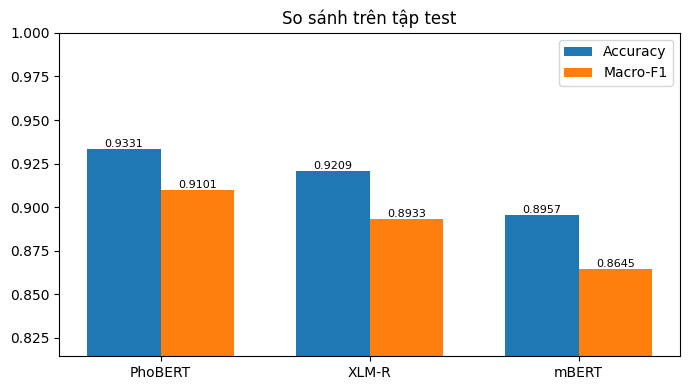

In [12]:
ten_model = list(KQ)
acc = [KQ[t]["accuracy"] for t in ten_model]
f1  = [KQ[t]["macro_f1"] for t in ten_model]
x, w = np.arange(len(ten_model)), 0.35

fig, ax = plt.subplots(figsize=(7, 4))
b1 = ax.bar(x - w / 2, acc, w, label="Accuracy")
b2 = ax.bar(x + w / 2, f1, w, label="Macro-F1")
ax.bar_label(b1, fmt="%.4f", fontsize=8)
ax.bar_label(b2, fmt="%.4f", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(ten_model)
ax.set_ylim(min(acc + f1) - 0.05, 1.0)
ax.set_title("So sánh trên tập test")
ax.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/bieu_do_1_accuracy_f1.png", dpi=150)
plt.show()

**Biểu đồ 2:** F1 theo từng nhãn. Cho biết model nào mạnh hoặc yếu ở nhãn nào.

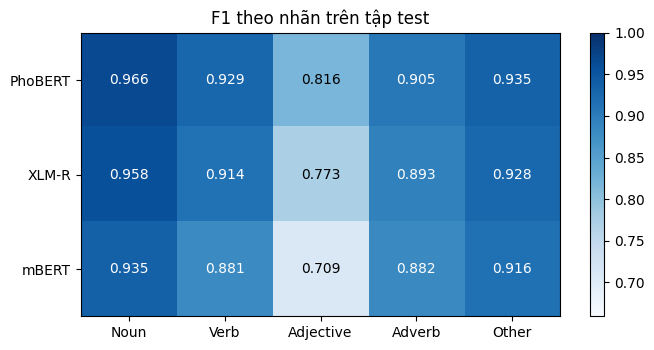

In [13]:
m = np.array([KQ[t]["f1_labels"] for t in ten_model])    # hàng = model, cột = nhãn
fig, ax = plt.subplots(figsize=(7, 1.2 + 0.8 * len(ten_model)))
im = ax.imshow(m, cmap="Blues", vmin=m.min() - 0.05, vmax=1.0, aspect="auto")
ax.set_xticks(range(len(LABELS)))
ax.set_xticklabels(LABELS)
ax.set_yticks(range(len(ten_model)))
ax.set_yticklabels(ten_model)
for i in range(m.shape[0]):
    for j in range(m.shape[1]):
        ax.text(j, i, f"{m[i, j]:.3f}", ha="center", va="center", color="white" if m[i, j] > (m.min() + 1) / 2 else "black")
ax.set_title("F1 theo nhãn trên tập test")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/bieu_do_2_f1_theo_nhan.png", dpi=150)
plt.show()

**Biểu đồ 3:** ma trận nhầm lẫn của từng model, chuẩn hóa theo hàng (mỗi ô là tỉ lệ từ có nhãn đúng ở hàng đó bị dự đoán thành nhãn ở cột).

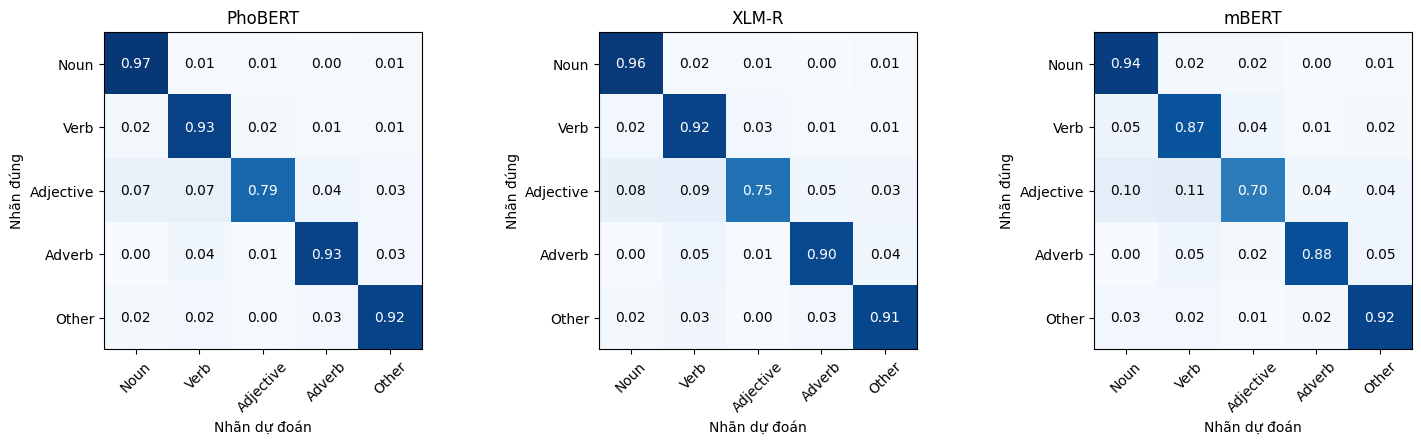

In [14]:
fig, axes = plt.subplots(1, len(ten_model), figsize=(5 * len(ten_model), 4.5), squeeze=False)
for ax, ten in zip(axes[0], ten_model):
    cm = KQ[ten]["cm"]
    cm_pt = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_pt, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=45)
    ax.set_yticks(range(len(LABELS)))
    ax.set_yticklabels(LABELS)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{cm_pt[i, j]:.2f}", ha="center", va="center", color="white" if cm_pt[i, j] > 0.5 else "black")
    ax.set_title(ten)
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn đúng")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/bieu_do_3_confusion_matrix.png", dpi=150)
plt.show()

**Biểu đồ 4:** quá trình huấn luyện của XLM-R và mBERT (loss và Accuracy trên Dev theo epoch).

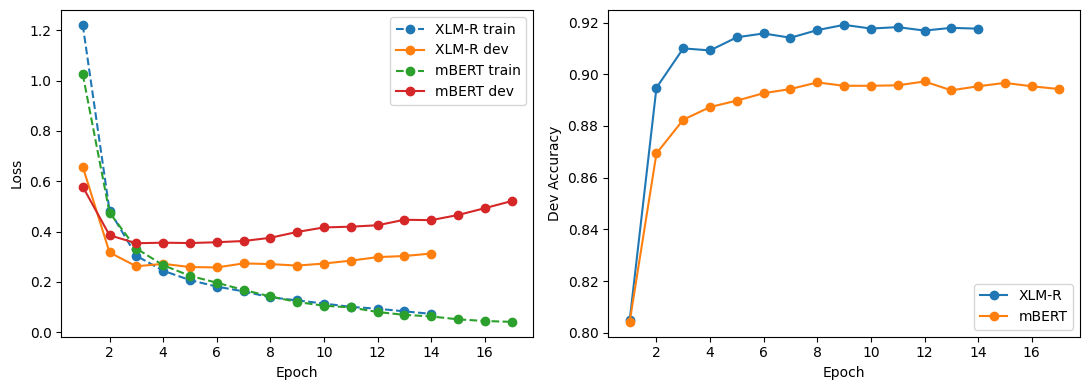

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for ten, h in HISTORY.items():
    ax1.plot(h["epoch"], h["train_loss"], marker="o", linestyle="--", label=f"{ten} train")
    ax1.plot(h["epoch"], h["dev_loss"], marker="o", label=f"{ten} dev")
    ax2.plot(h["epoch"], h["dev_accuracy"], marker="o", label=ten)
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss"); ax1.legend()
ax2.set_xlabel("Epoch"); ax2.set_ylabel("Dev Accuracy"); ax2.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/bieu_do_4_qua_trinh_train.png", dpi=150)
plt.show()

## 11. Hơn kém có thật hay chỉ do ngẫu nhiên? (khoảng tin cậy 95%)

Lấy mẫu lại **theo câu** (bootstrap) 1000 lần trên tập test, rồi xem hiệu Accuracy của từng model so với PhoBERT. Nếu khoảng tin cậy **không chứa 0** thì chênh lệch đáng tin ở mức đo trên tập test này.

Lưu ý: cách này chỉ tính dao động do chọn tập test, **chưa tính dao động do seed huấn luyện** (mỗi model mới chạy một seed).

In [16]:
n_tu = test["labels"].apply(len).to_numpy()                 # số từ của mỗi câu
bat_dau = np.r_[0, np.cumsum(n_tu)[:-1]]                    # vị trí bắt đầu của mỗi câu trong dãy nhãn

def dung_theo_cau(ten):
    dung = (np.array(KQ[ten]["y_true"]) == np.array(KQ[ten]["y_pred"])).astype(int)
    assert len(dung) == n_tu.sum()
    return np.add.reduceat(dung, bat_dau)                   # số từ đúng của mỗi câu

rng = np.random.default_rng(0)
idx = rng.integers(0, len(test), size=(1000, len(test)))    # 1000 lần lấy mẫu lại các câu
acc_boot = {t: dung_theo_cau(t)[idx].sum(axis=1) / n_tu[idx].sum(axis=1) for t in KQ}

for t in KQ:
    lo, hi = np.percentile(acc_boot[t], [2.5, 97.5])
    print(f"{t:8}: Accuracy {KQ[t]['accuracy']:.4f}  (95% CI: {lo:.4f} đến {hi:.4f})")

print()
for t in KQ:
    if t == "PhoBERT":
        continue
    lo, hi = np.percentile(acc_boot[t] - acc_boot["PhoBERT"], [2.5, 97.5])
    ket_luan = "khác biệt đáng tin" if (lo > 0 or hi < 0) else "chưa đủ bằng chứng là khác nhau"
    print(f"{t} - PhoBERT: hiệu Accuracy 95% CI {lo:+.4f} đến {hi:+.4f}  -> {ket_luan}")

PhoBERT : Accuracy 0.9331  (95% CI: 0.9282 đến 0.9381)
XLM-R   : Accuracy 0.9209  (95% CI: 0.9154 đến 0.9265)
mBERT   : Accuracy 0.8957  (95% CI: 0.8899 đến 0.9022)

XLM-R - PhoBERT: hiệu Accuracy 95% CI -0.0164 đến -0.0078  -> khác biệt đáng tin
mBERT - PhoBERT: hiệu Accuracy 95% CI -0.0427 đến -0.0319  -> khác biệt đáng tin


## 12. Nén kết quả để tải về (không gồm model)

In [17]:
# Chỉ gom file csv và png (bảng, dự đoán, log, biểu đồ), bỏ các thư mục model vì rất nặng
GOM_DIR = f"{OUT_DIR}_gon"
os.makedirs(GOM_DIR, exist_ok=True)
for f in os.listdir(OUT_DIR):
    if f.endswith((".csv", ".png")):
        shutil.copy(f"{OUT_DIR}/{f}", GOM_DIR)

shutil.make_archive("/content/ket_qua_so_sanh", "zip", GOM_DIR)
from google.colab import files
files.download("/content/ket_qua_so_sanh.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>